# Decision Tree: FARS Person-Level Data

## Load the data

Reads the person-level table saved by `load_fars_year.ipynb` from `processed/fars_<YEAR>_person.<LOAD_FORMAT>`. Run that notebook first for the year you want.

In [1]:
from pathlib import Path
import pandas as pd

YEAR = 2016
LOAD_FORMAT = "csv"   # "parquet" or "csv"
PROCESSED_DIR = Path("processed")

in_path = PROCESSED_DIR / f"fars_{YEAR}_person.{LOAD_FORMAT}"

if LOAD_FORMAT == "parquet":
    df = pd.read_parquet(in_path)
elif LOAD_FORMAT == "csv":
    df = pd.read_csv(in_path, low_memory=False)
else:
    raise ValueError('LOAD_FORMAT must be "parquet" or "csv"')

print(f"Loaded {in_path}: {df.shape[0]:,} people x {df.shape[1]} columns")
#df.head()

Loaded processed/fars_2016_person.csv: 86,474 people x 410 columns


In [2]:
ID_COLS = ["ST_CASE", "VEH_NO", "PER_NO", "YEAR", "STATE", "INJ_SEV"]  # key, split key, label source

BASE_COLS = [
    "AGE", "SEX", "PER_TYP", "SEAT_POS", "REST_USE", "BODY_TYP", "MOD_YEAR",
    "NUMOCCS", "TOW_VEH", "L_STATUS", "VSPD_LIM", "VALIGN", "VPROFILE",
    "VSURCOND", "VTRAFWAY", "VNUM_LAN", "VTRAFCON", "VTCONT_F", "HOUR",
    "DAY_WEEK", "MONTH", "RUR_URB", "FUNC_SYS", "LGT_COND", "WEATHER",
    "RELJCT2",
]
IMPACT_COLS = [
    "IMPACT1", "P_CRASH1", "P_CRASH2", "PCRASH4", "PCRASH5", "SPEEDREL",
    "DR_DRINK", "HARM_EV", "MAN_COLL", "REL_ROAD", "VE_FORMS", "PEDS",
    "PERNOTMVIT", "PERSONS", "PERMVIT", "DRUNK_DR",
]
POST_COLS = [
    "AIR_BAG", "EJECTION", "EXTRICAT", "ROLLOVER", "DEFORMED", "FIRE_EXP",
]

base_df             = df[ID_COLS + BASE_COLS]
base_impact_df      = df[ID_COLS + BASE_COLS + IMPACT_COLS]
base_impact_post_df = df[ID_COLS + BASE_COLS + IMPACT_COLS + POST_COLS]

In [3]:
print(f"BASE:               {len(BASE_COLS)} features")
print(f"BASE+IMPACT:        {len(BASE_COLS + IMPACT_COLS)} features")
print(f"BASE+IMPACT+POST:   {len(BASE_COLS + IMPACT_COLS + POST_COLS)} features")

BASE:               26 features
BASE+IMPACT:        42 features
BASE+IMPACT+POST:   48 features


In [4]:
FULL_SET = df[ID_COLS + BASE_COLS + IMPACT_COLS + POST_COLS].copy()

## PREPROCESSING STEP 1, Include binary output FATAL

In [5]:
# Keep only known injury levels 0-4 (drop 5 = severity unknown, 6 = died before crash, 9 = unknown)
FULL_SET = FULL_SET[FULL_SET["INJ_SEV"].between(0, 4)]

# Label: 1 = fatal (INJ_SEV 4), 0 = not fatal
FULL_SET["FATAL"] = (FULL_SET["INJ_SEV"] == 4).astype(int)

print(f"{len(FULL_SET):,} people remain")
FULL_SET["FATAL"].value_counts().sort_index()

84,823 people remain


FATAL
0    47017
1    37806
Name: count, dtype: int64

## PREPROCESS STEP 2, keep only vehicle occupants in dataset

In [6]:
# Keep only vehicle occupants: PER_TYP 1 = driver, 2 = passenger
FULL_SET = FULL_SET[FULL_SET["PER_TYP"].isin([1, 2])]

print(f"{len(FULL_SET):,} people remain")

76,695 people remain


## PREPROCESS STEP 3, one-hot encoding

In [7]:
# True numbers; everything else is a category code
NUMERIC_COLS = ["AGE", "MOD_YEAR", "NUMOCCS", "VSPD_LIM", "VE_FORMS",
                "PEDS", "PERNOTMVIT", "PERSONS", "PERMVIT"]
CATEGORICAL_COLS = [c for c in BASE_COLS + IMPACT_COLS + POST_COLS if c not in NUMERIC_COLS]

# One 0/1 column per code (e.g. BODY_TYP_4); unknown codes like 99 get their own column
FULL_SET[CATEGORICAL_COLS] = FULL_SET[CATEGORICAL_COLS].astype(int)
FULL_SET = pd.get_dummies(FULL_SET, columns=CATEGORICAL_COLS, dtype=int)

print(f"{FULL_SET.shape[1]} columns after one-hot encoding")

551 columns after one-hot encoding


## PREPROCESS STEP 4, remove rows with unknown values in the numeric columns

Crash data specifically, why drop? 
* NHTSA: NHTSA itself uses multiple imputation in FARS, to fill in missing blood alcohol concentration (BAC) values. Their technical reports document the method, which is a strong precedent that FARS unknowns matter.
* Jahan, Bhowmik, Hoover & Eluru (Transportation Research Record): in a crash-severity model on national CRSS data, multiple imputation fit better than dropping variables. Their simulations also found that dropping rows can be preferable when the sample is large and the missing share is small. That’s exactly your situation: 73,000 rows with 4.8% missing.
* Adediji & Noland (2020, Findings): imputing missing traffic volumes in a crash-count model noticeably shifted the coefficients. So imputation isn’t automatically safe either.


In [8]:
# FARS "unknown" codes in the numeric columns
UNKNOWN_CODES = {
    "AGE":      [998, 999],
    "MOD_YEAR": [9998, 9999],
    "NUMOCCS":  [97, 98, 99],
    "VSPD_LIM": [0, 98, 99],   # 0 = no statutory limit, treated as unknown
}

# Drop any row that has an unknown code in one of these columns
for col, codes in UNKNOWN_CODES.items():
    FULL_SET = FULL_SET[~FULL_SET[col].isin(codes)]

print(f"{len(FULL_SET):,} people remain")

72,525 people remain


In [9]:
# Save the preprocessed dataset (unscaled: trees do not need scaling)
out_path = Path("processed/decision_tree") / f"full_set_preprocessed_unscaled_{YEAR}.csv"
FULL_SET.to_csv(out_path, index=False)

print(f"Saved {out_path}: {FULL_SET.shape[0]:,} rows x {FULL_SET.shape[1]} columns")

Saved processed/decision_tree/full_set_preprocessed_unscaled_2016.csv: 72,525 rows x 551 columns


In [10]:
import re

# Model-ready feature lists for each tier, matched to the encoded column names
def encoded_cols(cols):
    out = []
    for col in cols:
        if col in NUMERIC_COLS:
            out.append(col)
        else:
            out += [c for c in FULL_SET.columns if re.fullmatch(rf"{col}_\d+", c)]
    return out

BASE_FEATURES             = encoded_cols(BASE_COLS)
BASE_IMPACT_FEATURES      = encoded_cols(BASE_COLS + IMPACT_COLS)
BASE_IMPACT_POST_FEATURES = encoded_cols(BASE_COLS + IMPACT_COLS + POST_COLS)

print(f"BASE:               {len(BASE_FEATURES)} columns")
print(f"BASE+IMPACT:        {len(BASE_IMPACT_FEATURES)} columns")
print(f"BASE+IMPACT+POST:   {len(BASE_IMPACT_POST_FEATURES)} columns")

# Usage:  X = FULL_SET[BASE_FEATURES];  y = FULL_SET["FATAL"];  groups = FULL_SET["STATE"]

BASE:               300 columns
BASE+IMPACT:        511 columns
BASE+IMPACT+POST:   544 columns


## DATA READY! Start here.

In [11]:
# ML-ready, processed datasets: IDs + label + that tier's features
base_df             = FULL_SET[ID_COLS + ["FATAL"] + BASE_FEATURES]
base_impact_df      = FULL_SET[ID_COLS + ["FATAL"] + BASE_IMPACT_FEATURES]
base_impact_post_df = FULL_SET[ID_COLS + ["FATAL"] + BASE_IMPACT_POST_FEATURES]

## 1. Train/test split by crash

Sort occupants by their ID columns (so the split is reproducible), then hold out 20% of **crashes** as the test set using `GroupShuffleSplit` (seed 522), with a crash identified by `YEAR`, `STATE`, `ST_CASE`. Everyone in the same crash ends up on the same side, so the model is never tested on a crash it trained on. Crashes have different numbers of occupants, so the test set is exactly 20% of crashes but only about 20% of occupants.

The table shows occupants, crashes, and fatal/nonfatal counts for each side. The test set is not used again until Section 4.

In [12]:
from sklearn.model_selection import GroupShuffleSplit

SEED = 522
CRASH_KEY = ["YEAR", "STATE", "ST_CASE"]
PERSON_KEY = CRASH_KEY + ["VEH_NO", "PER_NO"]

# One row per person, sorted so the split is reproducible.
assert not base_df[PERSON_KEY].isna().any().any(), "Missing ID values"
assert not base_df.duplicated(PERSON_KEY).any(), "Duplicate person rows"
model_df = base_df.sort_values(PERSON_KEY).reset_index(drop=True)

X = model_df[BASE_FEATURES]
y = model_df["FATAL"]
groups = model_df.groupby(CRASH_KEY).ngroup()  # one id per crash

# 80/20 split by crash: everyone in the same crash lands on the same side.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

split_table = pd.DataFrame({
    "occupants":   [len(y_train), len(y_test)],
    "crashes":     [g_train.nunique(), g_test.nunique()],
    "nonfatal":    [(y_train == 0).sum(), (y_test == 0).sum()],
    "fatal":       [y_train.sum(), y_test.sum()],
    "fatal_share": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_table)

,occupants,crashes,nonfatal,fatal,fatal_share
train,57864,26158,34524,23340,0.403360
test,14661,6540,8847,5814,0.396562


## 2. Baseline trees with cross-validation

The classes are close to balanced: about 40% of occupants are fatal (roughly 1.5 nonfatal per fatal) in both train and test, so no resampling or class weighting is used. Two baseline trees are compared:

- **Unrestricted**: grown until every leaf is pure.
- **Depth 4**: limited to 4 levels of splits.

Each tree is scored with 5-fold cross-validation on the training set only. `StratifiedGroupKFold` keeps whole crashes in one fold and keeps the fatal share similar across folds. The table shows each tree's mean **average precision (AP)** on the training folds (`train_ap`) and on the validation folds (`cv_ap`). AP summarizes how well the model ranks fatal occupants above nonfatal ones; a model with no skill scores about 0.40 (the fatal share). A large gap between the two columns means the tree is overfitting.

In [13]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

candidates = {
    "Unrestricted": DecisionTreeClassifier(random_state=SEED),
    "Depth 4":      DecisionTreeClassifier(max_depth=4, random_state=SEED),
}

# 5 folds within the training set; whole crashes stay together, fatal share roughly equal.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=g_train))

cv_rows = {}
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv_splits, scoring="average_precision",
                            return_train_score=True, n_jobs=2)
    cv_rows[name] = {"train_ap": scores["train_score"].mean(), "cv_ap": scores["test_score"].mean()}
cv_comparison = pd.DataFrame(cv_rows).T
display(cv_comparison.round(4))

,train_ap,cv_ap
Unrestricted,1.0000,0.5400
Depth 4,0.7239,0.7212


## 3. Grid search

Using the same 5 folds, `GridSearchCV` tries all 12 combinations of maximum depth (4, 8, unlimited), minimum leaf size (20, 100), and pruning strength `ccp_alpha` (0, 0.001). The combination with the highest mean validation AP (`cv_ap`) is refit on the full training set. The table shows all 12 combinations, best first, and the full results are saved to `processed/decision_tree/precrash_cv_2016.csv`.

The two baseline trees are then fit on the full training set, along with a majority-class dummy that always predicts nonfatal (a floor to compare against). The tuned model is chosen here, before any test results are seen.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV

RESULT_DIR = Path("processed/decision_tree")

# Try every combination below on the same 5 folds; refit the best (by mean validation AP)
# on the full training set.
param_grid = {
    "max_depth": [4, 8, None],
    "min_samples_leaf": [20, 100],
    "ccp_alpha": [0.0, 0.001],
}
search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid,
                      scoring="average_precision", cv=cv_splits, return_train_score=True, n_jobs=2)
search.fit(X_train, y_train)

cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_results.to_csv(RESULT_DIR / f"precrash_cv_{YEAR}.csv", index=False)
show = [f"param_{p}" for p in param_grid] + ["mean_train_score", "mean_test_score"]
display(cv_results[show].rename(columns={"mean_train_score": "train_ap", "mean_test_score": "cv_ap"})
        .round(4).fillna("none"))
print("Best parameters:", search.best_params_)
print(f"Best mean CV AP: {search.best_score_:.4f}")

# Fit the baselines on the full training set; the tuned model is already refit.
fitted_models = {name: model.fit(X_train, y_train) for name, model in candidates.items()}
fitted_models["Tuned (CV AP)"] = search.best_estimator_
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)  # always predicts nonfatal

# The model choice is fixed here, before any test results are seen.
selected_name = "Tuned (CV AP)"
selected_model = fitted_models[selected_name]

/Users/tyson/miniconda3/envs/cosc522/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,param_max_depth,param_min_samples_leaf,param_ccp_alpha,train_ap,cv_ap
5,none,100,0.000,0.8101,0.7863
3,8,100,0.000,0.7891,0.7783
2,8,20,0.000,0.7892,0.7712
4,none,20,0.000,0.8566,0.7658
8,8,20,0.001,0.7314,0.7287
9,8,100,0.001,0.7314,0.7287
10,none,20,0.001,0.7314,0.7287
11,none,100,0.001,0.7314,0.7287
1,4,100,0.000,0.7239,0.7213
0,4,20,0.000,0.7239,0.7212


Best parameters: {'ccp_alpha': 0.0, 'max_depth': None, 'min_samples_leaf': 100}
Best mean CV AP: 0.7863


## 4. Test-set evaluation

Each model (dummy, two baselines, tuned) is scored once on the held-out test set, using the default 0.5 probability cutoff to predict fatal vs nonfatal. Metrics, with fatal as the positive class: accuracy, balanced accuracy, precision, recall, F1, ROC-AUC and AP (both computed from predicted probabilities), plus confusion-matrix counts (TN, FP, FN, TP). The table is saved to `processed/decision_tree/precrash_test_metrics_2016.csv`.

A second table shows each tree's depth, number of leaves, and training accuracy. The plots show the confusion matrices (rows = actual, columns = predicted; green = correct, orange = false alarm, red = missed fatal) and the ROC and precision–recall curves. The dashed line on the precision–recall plot is the test-set fatal share, which is the AP a model with no skill would get.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,ap,TN,FP,FN,TP
model,,,,,,,,,,,
Majority dummy,0.6034,0.5000,0.0000,0.0000,0.0000,0.5000,0.3966,8847,0,5814,0
Unrestricted,0.6945,0.6834,0.6115,0.6299,0.6205,0.6833,0.5319,6520,2327,2152,3662
Depth 4,0.7512,0.7250,0.7261,0.5982,0.6560,0.7915,0.7221,7535,1312,2336,3478
Tuned (CV AP),0.7676,0.7426,0.7494,0.6219,0.6798,0.8332,0.7924,7638,1209,2198,3616


Test fatal share (AP of a no-skill model): 0.3966


,depth,leaves,train_accuracy
Unrestricted,50,11336,0.999706
Depth 4,4,16,0.744556
Tuned (CV AP),18,431,0.774298


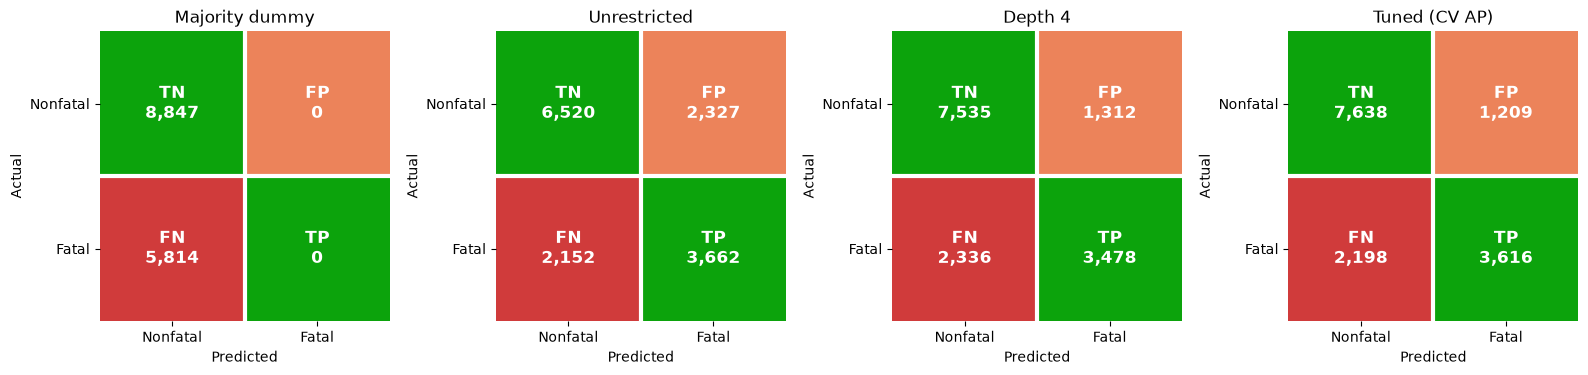

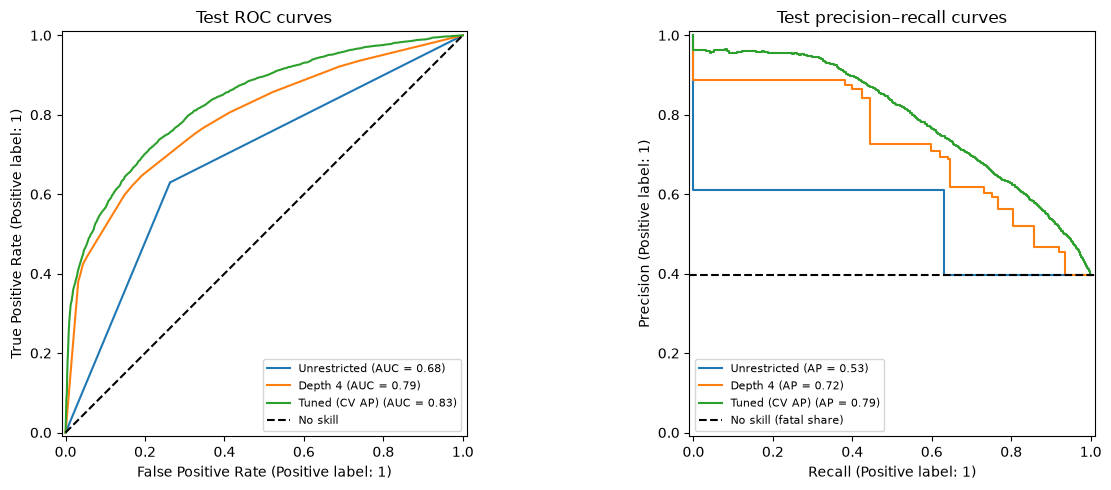

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay)

# Score every model once on the held-out test set (fatal = positive class).
all_models = {"Majority dummy": dummy, **fitted_models}
predictions, probabilities, rows = {}, {}, {}
for name, model in all_models.items():
    pred = predictions[name] = model.predict(X_test)                # 0.5 cutoff
    prob = probabilities[name] = model.predict_proba(X_test)[:, 1]  # P(fatal)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "ap": average_precision_score(y_test, prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }
test_results = pd.DataFrame.from_dict(rows, orient="index").rename_axis("model")
test_results.to_csv(RESULT_DIR / f"precrash_test_metrics_{YEAR}.csv")
display(test_results.round(4))
print(f"Test fatal share (AP of a no-skill model): {y_test.mean():.4f}")

# Size of each tree and how well it fits its own training data.
complexity = pd.DataFrame.from_dict({
    name: {"depth": m.get_depth(), "leaves": m.get_n_leaves(),
           "train_accuracy": m.score(X_train, y_train)}
    for name, m in fitted_models.items()}, orient="index")
display(complexity)

# Confusion matrices: rows = actual, columns = predicted.
# Colored by outcome: green = correct, orange = false alarm, red = missed fatal.
CELLS = [["TN", "FP"], ["FN", "TP"]]
CELL_COLORS = {"TN": "#0ca30c", "TP": "#0ca30c", "FP": "#ec835a", "FN": "#d03b3b"}
fig, axes = plt.subplots(1, len(all_models), figsize=(4 * len(all_models), 3.7))
for ax, name in zip(axes, all_models):
    cm = confusion_matrix(y_test, predictions[name])
    ax.imshow([[to_rgb(CELL_COLORS[c]) for c in row] for row in CELLS])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{CELLS[i][j]}\n{cm[i, j]:,}", ha="center", va="center",
                    color="white", fontsize=12, fontweight="bold")
    ax.axhline(0.5, color="white", linewidth=3)
    ax.axvline(0.5, color="white", linewidth=3)
    ax.spines[:].set_visible(False)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Nonfatal", "Fatal"],
           yticklabels=["Nonfatal", "Fatal"], xlabel="Predicted", ylabel="Actual", title=name)
fig.tight_layout()
plt.show()

# ROC and precision-recall curves; dashed lines show a no-skill model.
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(13, 5))
for name in fitted_models:
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=roc_ax)
    PrecisionRecallDisplay.from_predictions(y_test, probabilities[name], name=name, ax=pr_ax)
roc_ax.plot([0, 1], [0, 1], "k--", label="No skill")
pr_ax.axhline(y_test.mean(), color="black", linestyle="--", label="No skill (fatal share)")
roc_ax.set_title("Test ROC curves")
pr_ax.set_title("Test precision–recall curves")
for ax in (roc_ax, pr_ax):
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Tree diagrams and feature importance

The diagram shows the full depth-4 tree (16 leaves). Node values are the share of nonfatal/fatal training occupants in that node, and a split on a one-hot column at 0.5 separates occupants who have that code from those who don't. The unrestricted and tuned trees are too large to draw readably (see their depth and leaf counts in Section 4); their first 3 levels are identical to this tree's.

The chart shows the tuned model's 15 most important one-hot columns: how much each one reduced impurity across the tree's splits. The table lists every column the tuned tree used (importance above 0), and all 300 values are saved to `processed/decision_tree/precrash_importances_2016.csv`. Importance shows what the model relied on, not cause and effect.

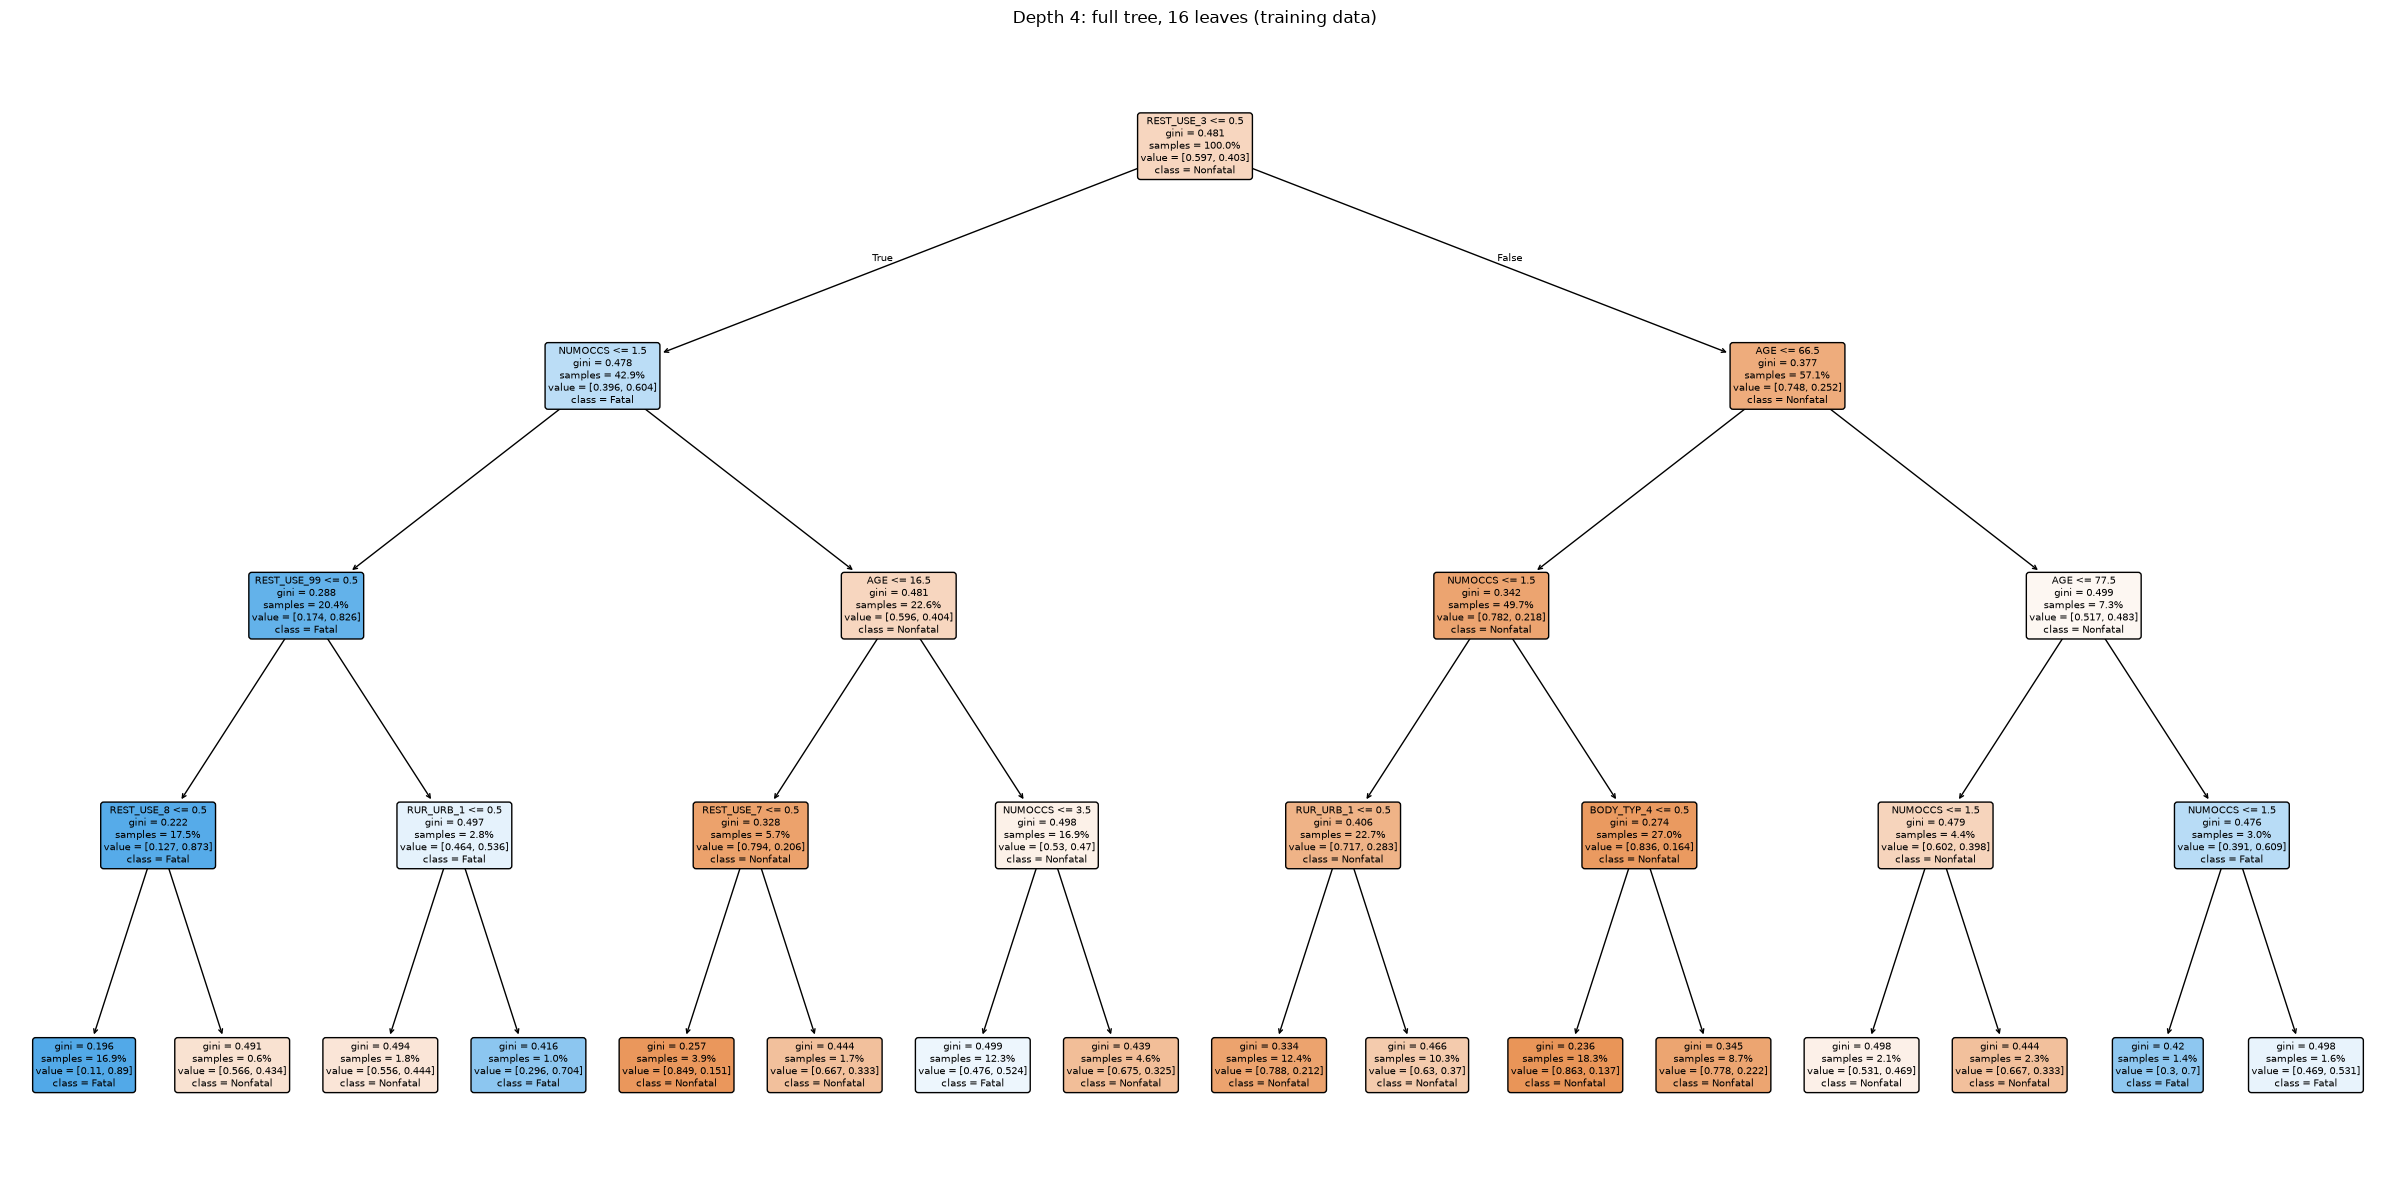

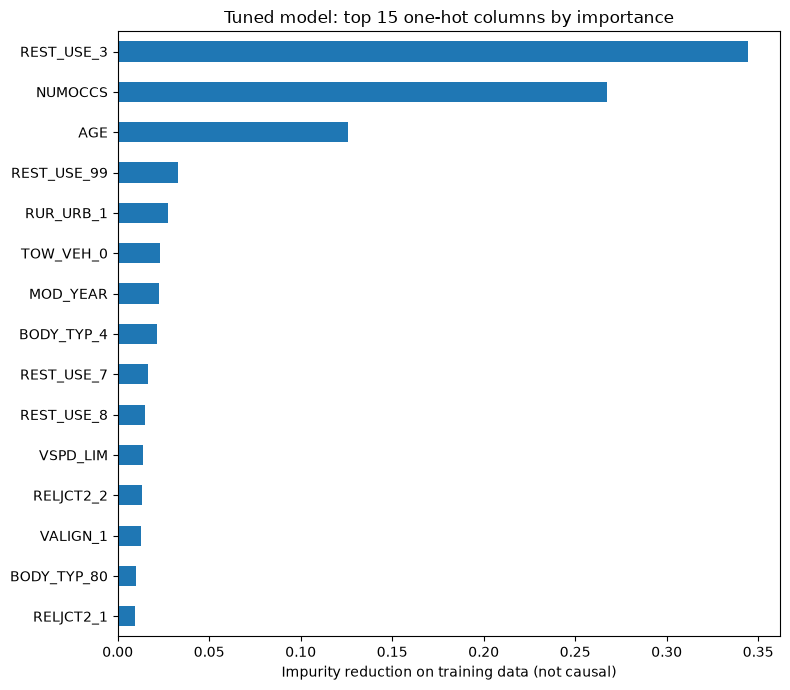

,importance
REST_USE_3,0.344689
NUMOCCS,0.267269
AGE,0.125732
REST_USE_99,0.033061
RUR_URB_1,0.027353
TOW_VEH_0,0.022939
MOD_YEAR,0.022672
BODY_TYP_4,0.021271
REST_USE_7,0.016497
REST_USE_8,0.014660


In [16]:
from sklearn.tree import plot_tree

# Full depth-4 tree. Node values = share of nonfatal/fatal training occupants.
fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(fitted_models["Depth 4"], feature_names=X_train.columns, class_names=["Nonfatal", "Fatal"],
          filled=True, rounded=True, proportion=True, fontsize=7, ax=ax)
ax.set_title("Depth 4: full tree, 16 leaves (training data)")
fig.tight_layout()
plt.show()

# Tuned model: importance of each one-hot column (e.g. REST_USE_3 = restraint-use code 3).
importances = pd.Series(selected_model.feature_importances_, index=X_train.columns,
                        name="importance").sort_values(ascending=False)
importances.to_csv(RESULT_DIR / f"precrash_importances_{YEAR}.csv", index_label="encoded_feature")

ax = importances.head(15).sort_values().plot.barh(figsize=(8, 7))
ax.set_title("Tuned model: top 15 one-hot columns by importance")
ax.set_xlabel("Impurity reduction on training data (not causal)")
plt.tight_layout()
plt.show()
display(importances[importances > 0].to_frame())  # columns the tuned tree actually split on

## 6. Medium-truck count (descriptive only)

Counts occupants and unique vehicles in the modeling data whose `BODY_TYP` is a medium truck: codes 60, 61, 62, 64, 67, 71, per the NHTSA manual's Appendix C, *Vehicle Classification by NCSA Data Elements* (pp. C-29–C-30). `BODY_TYP` is recovered from its one-hot columns. Vehicles are counted separately because one truck can carry several occupants; the last row gives totals. Nothing here changes the model or the data.

In [17]:
MEDIUM_TRUCK_BODY_TYPES = [60, 61, 62, 64, 67, 71]  # NHTSA manual, Appendix C

# BODY_TYP is one-hot encoded; recover each occupant's code from its dummy columns.
body_typ = model_df.filter(regex=r"^BODY_TYP_\d+$").idxmax(axis=1).str.removeprefix("BODY_TYP_").astype(int)
medium = model_df.assign(BODY_TYP=body_typ)[body_typ.isin(MEDIUM_TRUCK_BODY_TYPES)]
vehicles = medium.drop_duplicates(CRASH_KEY + ["VEH_NO"])  # one row per truck

truck_counts = pd.DataFrame({"occupants": medium["BODY_TYP"].value_counts(),
                             "unique_vehicles": vehicles["BODY_TYP"].value_counts()}).sort_index()
truck_counts.loc["total"] = truck_counts.sum()
display(truck_counts)

,occupants,unique_vehicles
BODY_TYP,,
60,6,6
61,427,315
62,215,167
64,290,228
67,541,351
71,13,11
total,1492,1078


## 7. Summary and limitations

The cell below first checks that every model input comes from a pre-crash (`BASE_COLS`) field, then writes a summary using this run's actual results: cohort size, the tuned model's test metrics, a baseline comparison, and the tuned model's top 5 one-hot columns by importance.

Limitations to keep in mind:

- FARS only contains crashes in which someone died, so these results describe fatality risk *within fatal crashes*, not across all crashes.
- Some pre-crash fields, such as `REST_USE` (restraint use), are recorded by police after the crash.
- The test set separates crashes but not states. Every occupant counts equally, so crashes with more occupants carry more weight.
- Tree probabilities are not calibrated, so a predicted 0.7 does not necessarily mean a 70% chance of death.

In [18]:
from IPython.display import Markdown

# Every model input must come from a pre-crash (BASE) field: strip the one-hot suffix and check.
input_fields = set(X_train.columns.str.replace(r"_\d+$", "", regex=True))
assert input_fields <= set(BASE_COLS), f"Non-base inputs: {input_fields - set(BASE_COLS)}"

tuned = test_results.loc[selected_name]
unrestricted = test_results.loc["Unrestricted"]
depth4 = test_results.loc["Depth 4"]
display(Markdown(f"""
**Data:** {len(y):,} occupants from {groups.nunique():,} crashes. The test set has {len(y_test):,} occupants
from {g_test.nunique():,} crashes, none of which were used in training.

**Tuned tree on the test set:** accuracy **{tuned['accuracy']:.3f}**, balanced accuracy
**{tuned['balanced_accuracy']:.3f}**, precision **{tuned['precision']:.3f}**, recall **{tuned['recall']:.3f}**,
F1 **{tuned['f1']:.3f}**, ROC-AUC **{tuned['roc_auc']:.3f}**, AP **{tuned['ap']:.3f}**
(a no-skill model scores AP {y_test.mean():.3f}).

**Baselines:** unrestricted vs depth 4: balanced accuracy {unrestricted['balanced_accuracy']:.3f} vs
{depth4['balanced_accuracy']:.3f}; AP {unrestricted['ap']:.3f} vs {depth4['ap']:.3f}.
Compare the train vs CV AP and leaf counts above for overfitting.

**Most important one-hot columns (tuned model):** {", ".join(importances.head(5).index)}.
These are associations within FARS fatal crashes, not causal effects.
"""))


**Data:** 72,525 occupants from 32,698 crashes. The test set has 14,661 occupants
from 6,540 crashes, none of which were used in training.

**Tuned tree on the test set:** accuracy **0.768**, balanced accuracy
**0.743**, precision **0.749**, recall **0.622**,
F1 **0.680**, ROC-AUC **0.833**, AP **0.792**
(a no-skill model scores AP 0.397).

**Baselines:** unrestricted vs depth 4: balanced accuracy 0.683 vs
0.725; AP 0.532 vs 0.722.
Compare the train vs CV AP and leaf counts above for overfitting.

**Most important one-hot columns (tuned model):** REST_USE_3, NUMOCCS, AGE, REST_USE_99, RUR_URB_1.
These are associations within FARS fatal crashes, not causal effects.
